# Chapter 11: Exploring Data Over Time

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 11.1 Dates in pandas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('book.mplstyle')

orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])
visitors = pd.read_csv('ab_test.csv', parse_dates=['visit_date'])
orders[['order_id', 'order_date', 'order_type', 'amount']].head()

,order_id,order_date,order_type,amount
0,100001,2024-01-01,Subscription,8.0
1,100002,2024-01-01,Subscription,8.0
2,100003,2024-01-01,Subscription,14.0
3,100004,2024-01-02,Subscription,8.0
4,100005,2024-01-02,Subscription,8.0


### `s.dt`

In [2]:
order_dates = orders['order_date']
pd.DataFrame({'date': order_dates,
              'year': order_dates.dt.year,
              'month': order_dates.dt.month,
              'weekday': order_dates.dt.day_name()}).tail(3)

,date,year,month,weekday
28769,2025-12-31,2025,12,Wednesday
28770,2025-12-31,2025,12,Wednesday
28771,2025-12-31,2025,12,Wednesday


In [3]:
yearly_revenue = orders.groupby(order_dates.dt.year)['amount'].sum()
print(yearly_revenue.round(2))
growth = yearly_revenue[2025] / yearly_revenue[2024]
print(f'2025 revenue is {growth:.2f} times 2024 revenue')

order_date
2024    206177.65
2025    568879.41
Name: amount, dtype: float64
2025 revenue is 2.76 times 2024 revenue


### `s.dt.to_period()`

In [4]:
order_months = order_dates.dt.to_period('M')
monthly_orders = orders.groupby(order_months).size()
monthly_orders.tail(3)

order_date
2025-10    1919
2025-11    2159
2025-12    2620
Freq: M, dtype: int64

## 11.2 Totals per Month, Week and Quarter

### `df.resample()`

In [5]:
monthly_revenue = orders.resample('ME', on='order_date')['amount'].sum()
monthly_revenue.round(2).head()

order_date
2024-01-31     1696.93
2024-02-29     4663.43
2024-03-31     7662.32
2024-04-30     9956.91
2024-05-31    12813.18
Freq: ME, Name: amount, dtype: float64

In [6]:
quarterly = orders.resample('QE', on='order_date')['amount'].sum()
quarterly.round(0)

order_date
2024-03-31     14023.0
2024-06-30     38036.0
2024-09-30     60197.0
2024-12-31     93922.0
2025-03-31    111526.0
2025-06-30    126554.0
2025-09-30    145190.0
2025-12-31    185609.0
Freq: QE-DEC, Name: amount, dtype: float64

### `s.plot()`

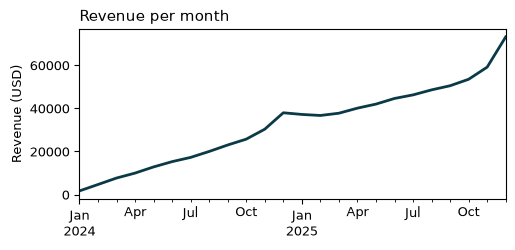

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
monthly_revenue.plot(ax=ax, color='#0b3a47')
ax.set_title('Revenue per month')
ax.set_xlabel('')
ax.set_ylabel('Revenue (USD)')
plt.show()

### More than one number per period

In [8]:
monthly = orders.resample('ME', on='order_date').agg(
    revenue=('amount', 'sum'),
    customers=('customer_id', 'nunique'))
monthly['per_customer'] = monthly['revenue'] / monthly['customers']
monthly.round(2).loc['2024-12':]

,revenue,customers,per_customer
order_date,,,
2024-12-31,37919.21,1084,34.98
2025-01-31,37145.61,1133,32.79
2025-02-28,36666.01,1170,31.34
2025-03-31,37714.68,1200,31.43
2025-04-30,40064.00,1285,31.18
2025-05-31,41938.48,1339,31.32
2025-06-30,44551.31,1389,32.07
2025-07-31,46205.17,1438,32.13
2025-08-31,48532.47,1493,32.51


## 11.3 Change from One Month to the Next

### `s.shift()`

In [9]:
change = pd.DataFrame({'revenue': monthly_revenue})
change['last_month'] = change['revenue'].shift(1)
change.round(2).head(3)

,revenue,last_month
order_date,,
2024-01-31,1696.93,NaN
2024-02-29,4663.43,1696.93
2024-03-31,7662.32,4663.43


### `s.diff()`

In [10]:
change['change'] = change['revenue'].diff()
change.round(2).tail(3)

,revenue,last_month,change
order_date,,,
2025-10-31,53445.00,50452.50,2992.50
2025-11-30,59077.52,53445.00,5632.52
2025-12-31,73086.66,59077.52,14009.14


### `s.pct_change()`

In [11]:
change['month_on_month'] = change['revenue'].pct_change()
change['year_on_year'] = change['revenue'].pct_change(12)
change[['revenue', 'month_on_month', 'year_on_year']].round(3).tail()

,revenue,month_on_month,year_on_year
order_date,,,
2025-08-31,48532.47,0.050,1.429
2025-09-30,50452.50,0.040,1.196
2025-10-31,53445.00,0.059,1.080
2025-11-30,59077.52,0.105,0.949
2025-12-31,73086.66,0.237,0.927


## 11.4 Smoothing a Noisy Series

In [12]:
add_ons = orders[orders['order_type'] == 'Add-on']
weekly_add_ons = add_ons.resample('W', on='order_date').size()
weekly_add_ons.tail(3)

order_date
2025-12-21    164
2025-12-28    171
2026-01-04     62
Freq: W-SUN, dtype: int64

In [13]:
weekly_add_ons = weekly_add_ons.loc[:'2025-12-28']
print(f'{len(weekly_add_ons)} full weeks, '
      f'last one ends {weekly_add_ons.index[-1]:%B %d, %Y}')

103 full weeks, last one ends December 28, 2025


### `s.rolling()`

In [14]:
smooth = pd.DataFrame({'orders': weekly_add_ons})
smooth['trailing'] = weekly_add_ons.rolling(4).mean()
smooth['centered'] = weekly_add_ons.rolling(4, center=True).mean()
smooth.loc['2024-12-01':'2025-01-12']

,orders,trailing,centered
order_date,,,
2024-12-01,73,49.50,62.50
2024-12-08,80,62.50,71.00
2024-12-15,79,71.00,79.75
2024-12-22,87,79.75,88.75
2024-12-29,109,88.75,90.25
2025-01-05,86,90.25,89.75
2025-01-12,77,89.75,83.00


### Centered or trailing

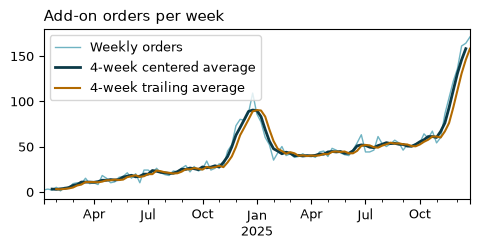

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
smooth['orders'].plot(ax=ax, color='#6fb3c2', linewidth=1,
                      label='Weekly orders')
smooth['centered'].plot(ax=ax, color='#0b3a47',
                        label='4-week centered average')
smooth['trailing'].plot(ax=ax, color='#b26a00', linewidth=1.5,
                        label='4-week trailing average')
ax.set_title('Add-on orders per week')
ax.set_xlabel('')
ax.legend(loc='upper left')
plt.show()

## 11.5 Trend and Seasons

### Lining up the years

In [16]:
add_ons = add_ons.assign(year=add_ons['order_date'].dt.year,
                         month=add_ons['order_date'].dt.month)
add_on_months = add_ons.pivot_table(
    values='order_id', index='month', columns='year',
    aggfunc='count')
add_on_months.tail(4)

year,2024,2025
month,,
9,110,219
10,122,264
11,205,388
12,392,694


year    2024   2025
month              
10     0.095  0.082
11     0.159  0.120
12     0.304  0.215


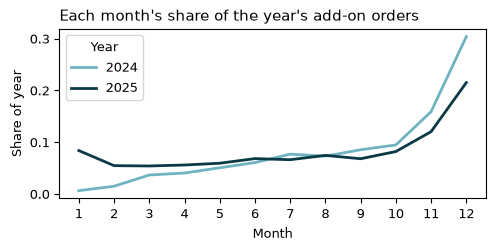

In [17]:
season_share = add_on_months / add_on_months.sum()
print(season_share.round(3).tail(3))

fig, ax = plt.subplots(figsize=(5.5, 2.2))
season_share.plot(ax=ax, color=['#6fb3c2', '#0b3a47'])
ax.set_title("Each month's share of the year's add-on orders")
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month')
ax.set_ylabel('Share of year')
ax.legend(title='Year')
plt.show()

### Seasons in delivery times

In [18]:
orders['late'] = orders['delivery_days'] > 5
orders['december'] = order_dates.dt.month == 12
orders.groupby([order_dates.dt.year, 'december'])[
    ['delivery_days', 'late']].mean().round(3)

delivery_days   late
order_date december                      
2024       False             3.243  0.090
           True              3.858  0.157
2025       False             3.197  0.076
           True              3.815  0.150

## 11.6 Cohorts and Retention

### Labeling each customer's cohort

In [19]:
customers['cohort'] = customers['signup_date'].dt.to_period('M')
customers['cohort'].value_counts().sort_index().head(3)

cohort
2024-01    123
2024-02    127
2024-03    107
Freq: M, Name: count, dtype: int64

### Months since sign-up

In [20]:
boxes = orders[orders['order_type'] == 'Subscription'].merge(
    customers[['customer_id', 'signup_date', 'cohort']],
    on='customer_id', validate='many_to_one')
years_apart = (boxes['order_date'].dt.year
               - boxes['signup_date'].dt.year)
months_apart = (boxes['order_date'].dt.month
                - boxes['signup_date'].dt.month)
boxes['month_number'] = years_apart * 12 + months_apart
boxes.loc[boxes['customer_id'] == 1003,
          ['signup_date', 'order_date', 'month_number']].head(4)

,signup_date,order_date,month_number
2,2024-01-01,2024-01-01,0
124,2024-01-01,2024-02-01,1
350,2024-01-01,2024-03-01,2
648,2024-01-01,2024-04-01,3


### The cohort table

In [21]:
cohort_counts = boxes.pivot_table(
    values='customer_id', index='cohort', columns='month_number',
    aggfunc='nunique')
cohort_counts.iloc[:4, :6]

month_number,0,1,2,3,4,5
cohort,,,,,,
2024-01,123.0,99.0,85.0,75.0,70.0,64.0
2024-02,127.0,106.0,88.0,74.0,65.0,60.0
2024-03,107.0,93.0,79.0,67.0,62.0,59.0
2024-04,124.0,98.0,84.0,76.0,67.0,65.0


In [22]:
cohort_counts.iloc[-4:, :6]

month_number,0,1,2,3,4,5
cohort,,,,,,
2025-09,222.0,185.0,166.0,149.0,NaN,NaN
2025-10,205.0,178.0,153.0,NaN,NaN,NaN
2025-11,263.0,229.0,NaN,NaN,NaN,NaN
2025-12,311.0,NaN,NaN,NaN,NaN,NaN


### From counts to retention

In [23]:
cohort_size = cohort_counts[0]
retention = cohort_counts.div(cohort_size, axis=0)
retention.iloc[:4, :6].round(2)

month_number,0,1,2,3,4,5
cohort,,,,,,
2024-01,1.0,0.80,0.69,0.61,0.57,0.52
2024-02,1.0,0.83,0.69,0.58,0.51,0.47
2024-03,1.0,0.87,0.74,0.63,0.58,0.55
2024-04,1.0,0.79,0.68,0.61,0.54,0.52


### A retention heatmap

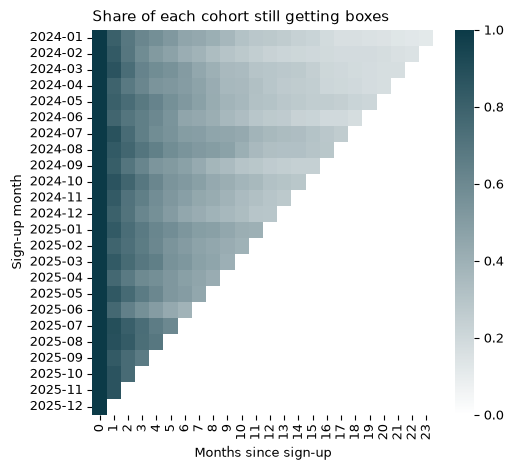

In [24]:
retention_cmap = sns.blend_palette(['white', '#0b3a47'],
                                   as_cmap=True)
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(retention, vmin=0, vmax=1, cmap=retention_cmap, ax=ax)
ax.set_title('Share of each cohort still getting boxes')
ax.set_xlabel('Months since sign-up')
ax.set_ylabel('Sign-up month')
plt.show()

### Comparing cohorts before and after July 2025

In [25]:
new_email = retention.index >= pd.Period('2025-07', freq='M')
compare = pd.DataFrame({
    'before': retention[~new_email].mean(),
    'from_july': retention[new_email].mean(),
    'july_cohorts': retention[new_email].count()})
compare.loc[1:5].round(3)

,before,from_july,july_cohorts
month_number,,,
1,0.820,0.870,5
2,0.720,0.784,4
3,0.641,0.715,3
4,0.583,0.675,2
5,0.530,0.605,1


In [26]:
early_2025 = retention.loc['2025-01':'2025-06', 3].mean()
print(f'Month-3 retention, Jan-Jun 2025 cohorts: {early_2025:.3f}')

Month-3 retention, Jan-Jun 2025 cohorts: 0.643


## 11.7 Churn Rate

In [27]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
print(f"Ever cancelled: {customers['cancelled'].mean():.1%}")
signup_year = customers['signup_date'].dt.year
customers.groupby(signup_year)['cancelled'].mean().round(3)

Ever cancelled: 56.3%


signup_date
2024    0.777
2025    0.406
Name: cancelled, dtype: float64

### Monthly churn

In [28]:
customers = customers.merge(
    cancellations[['customer_id', 'cancel_date']],
    on='customer_id', how='left', validate='one_to_one')
data_end = pd.Timestamp('2025-12-31')
customers['end_date'] = customers['cancel_date'].fillna(data_end)
customers['cancel_month'] = customers['cancel_date'].dt.to_period('M')
customers[['signup_date', 'end_date', 'cancel_month']].head(3)

,signup_date,end_date,cancel_month
0,2024-01-01,2025-12-31,NaT
1,2024-01-01,2024-01-08,2024-01
2,2024-01-01,2025-04-26,2025-04


In [29]:
rows = []
for month in pd.period_range('2024-02', '2025-12', freq='M'):
    start = month.start_time
    active = customers[(customers['signup_date'] < start)
                       & (customers['end_date'] >= start)]
    left = active['cancel_month'] == month
    rows.append({'month': month, 'active': len(active),
                 'cancelled': left.sum(), 'churn': left.mean()})
churn = pd.DataFrame(rows).set_index('month')
churn.round(3).tail()

,active,cancelled,churn
month,,,
2025-08,1375,125,0.091
2025-09,1430,100,0.070
2025-10,1530,139,0.091
2025-11,1586,122,0.077
2025-12,1712,160,0.093


In [30]:
churn['rolling_3'] = churn['churn'].rolling(3).mean()
churn['rolling_3'].dropna().round(3).iloc[[0, -1]]

month
2024-04    0.153
2025-12    0.087
Freq: M, Name: rolling_3, dtype: float64

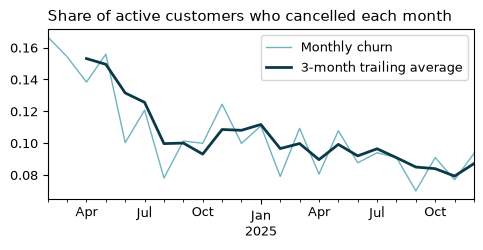

In [31]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
churn['churn'].plot(ax=ax, color='#6fb3c2', linewidth=1,
                    label='Monthly churn')
churn['rolling_3'].plot(ax=ax, color='#0b3a47',
                        label='3-month trailing average')
ax.set_title('Share of active customers who cancelled each month')
ax.set_xlabel('')
ax.legend()
plt.show()

In [32]:
churn.groupby(churn.index.year)['churn'].mean().round(3)

month
2024    0.122
2025    0.091
Name: churn, dtype: float64

## 11.8 Conversion Funnels

In [33]:
steps = ['viewed_plans', 'started_checkout', 'purchased']
print(f'{len(visitors):,} visitors')
print(f"First visit: {visitors['visit_date'].min().date()}")
print(f"Last visit:  {visitors['visit_date'].max().date()}")
visitors[steps].head()

22,756 visitors
First visit: 2025-10-06
Last visit:  2025-11-02


,viewed_plans,started_checkout,purchased
0,1,1,0
1,0,0,0
2,0,0,0
3,1,0,0
4,0,0,0


In [34]:
skipped = ((visitors['started_checkout'] > visitors['viewed_plans'])
           | (visitors['purchased'] > visitors['started_checkout']))
print(f'Visitors who skipped a step: {skipped.sum()}')

Visitors who skipped a step: 0


### Counting each step

In [35]:
funnel = pd.Series({
    'visited': len(visitors),
    'viewed plans': visitors['viewed_plans'].sum(),
    'started checkout': visitors['started_checkout'].sum(),
    'purchased': visitors['purchased'].sum()})
funnel_table = pd.DataFrame({
    'people': funnel,
    'from_last_step': funnel / funnel.shift(1),
    'from_start': funnel / funnel.iloc[0]})
funnel_table.round(3)

,people,from_last_step,from_start
visited,22756,NaN,1.000
viewed plans,12380,0.544,0.544
started checkout,6450,0.521,0.283
purchased,1975,0.306,0.087


### Charting the funnel

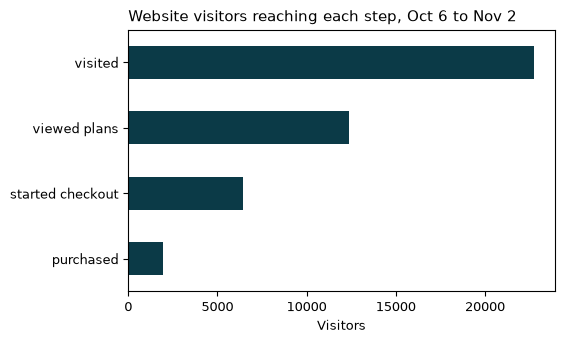

In [36]:
ax = funnel.plot.barh(color='#0b3a47')
ax.invert_yaxis()
ax.set_title('Website visitors reaching each step, Oct 6 to Nov 2')
ax.set_xlabel('Visitors')
plt.show()